In [1]:
import numpy as np
import pandas as pd
import math

import os

import torch
import torchvision
import torchvision.datasets
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
from torchsummary import summary
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil, sqrt
from tqdm.notebook import tqdm

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Dataset

In [3]:
img_dir = '/kaggle/input/datasets/msheriey/104-flowers-garden-of-eden/jpeg-192x192'

In [4]:
class Flower104(Dataset):
    def __init__(self, split='train', transform=None):
        self.img_dir = img_dir + '/' + split
        image_paths = [list(map(lambda name: class_name + '/' + name, os.listdir(self.img_dir + '/' + class_name))) for class_name in os.listdir(self.img_dir)]
        image_paths = sum(image_paths, [])
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.image_paths[idx])
        img = Image.open(img_path).convert('RGB')
        return self.transform(img)

In [183]:
WIDTH = 32

MEAN = [0.4475, 0.4168, 0.2963]
STD = [0.2791, 0.2415, 0.2653]

transform = transforms.Compose([
    transforms.Resize((WIDTH, WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ = Flower104(split='train', transform=transform)
test_ = Flower104(split='val', transform=transform)

BATCH_SIZE = 64
N_CHANNELS = train_[0].size(0)
WIDTH = train_[0].size(1)

train_loader = DataLoader(train_, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_, batch_size=BATCH_SIZE, shuffle=False)

In [184]:
train_.__len__()

12753

In [185]:
next(iter(train_loader)).mean(dim=(0, 2, 3)), next(iter(train_loader)).std(dim=(0, 2, 3))

(tensor([0.0889, 0.0060, 0.0044]), tensor([0.9349, 0.8950, 0.9206]))

In [186]:
def show_image(images: torch.Tensor, titles: list[str] = None, n_cols: int = None):
    """
    Рисует одну картинку или батч картинок из torch.Tensor.

    Args:
        images: тензор shape (C, H, W) для одной картинки
                или (B, C, H, W) для батча
        titles: список заголовков длиной B (опционально)
        n_cols: количество колонок в сетке. По умолчанию ~sqrt(B)
    """
    # Переносим на CPU и отключаем градиенты
    imgs = images.detach().cpu()

    # Если одна картинка (CHW), оборачиваем в батч
    if imgs.ndim == 3:
        imgs = imgs.unsqueeze(0)

    b = imgs.shape[0]

    # Определяем размер сетки
    if n_cols is None:
        n_cols = b
    n_rows = ceil(b / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))

    # Если всего одна картинка, axes не будет массивом
    if b == 1 and n_rows == 1 and n_cols == 1:
        axes = [[axes]]
    elif n_rows == 1:
        axes = [axes]
    elif n_cols == 1:
        axes = [[ax] for ax in axes]

    for idx in range(n_rows * n_cols):
        row, col = idx // n_cols, idx % n_cols
        ax = axes[row][col]

        if idx < b:
            img = imgs[idx].permute(1, 2, 0)  # CHW -> HWC

            # Grayscale
            if img.shape[2] == 1:
                img = img.squeeze(2)

            # Нормализуем в [0, 1] если нужно
            if img.max() > 1.0 or img.min() < 0.0:
                img = (img - img.min()) / (img.max() - img.min() + 1e-8)

            ax.imshow(img, cmap='gray' if img.ndim == 2 else None)

            if titles and idx < len(titles):
                ax.set_title(titles[idx], fontsize=9)
        else:
            # Пустые ячейки, если батч не заполняет сетку целиком
            pass

        ax.axis('off')

    plt.tight_layout()
    plt.show()

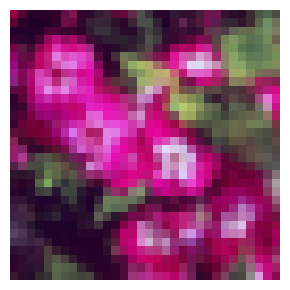

In [187]:
show_image(train_[0])

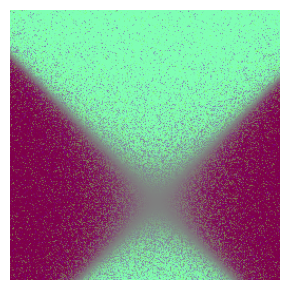

In [188]:
width = 128
size = 5
image = torch.tensor([[[np.tanh(((i - size / 2 + j) * np.random.random() * .5 * (i - j - size / 3))) * np.tan(c ** 5) for j in np.arange(-size, size, size / width)] for i in np.arange(-size, size, size / width)] for c in range(3)], dtype=torch.float32)
show_image(image)

## Modeling

In [189]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return emb

class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.sin_emb = SinusoidalPosEmb(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.SiLU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, t):
        x = self.sin_emb(t)
        return self.mlp(x)

import torch
import torch.nn as nn
import torch.nn.functional as F

class FastDiTBlock(nn.Module):
    def __init__(self, hidden_dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        
        self.norm1 = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)
        self.qkv = nn.Linear(hidden_dim, hidden_dim * 3)
        self.proj = nn.Linear(hidden_dim, hidden_dim)

        self.norm2 = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 4),
            nn.GELU(approximate="tanh"),
            nn.Linear(hidden_dim * 4, hidden_dim)
        )

        self.adaLN_modulation = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_dim, 6 * hidden_dim)
        )

    def forward(self, x, c):
        shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = self.adaLN_modulation(c).chunk(6, dim=-1)

        shift_msa = shift_msa.unsqueeze(1)
        scale_msa = scale_msa.unsqueeze(1)
        gate_msa = gate_msa.unsqueeze(1)
        shift_mlp = shift_mlp.unsqueeze(1)
        scale_mlp = scale_mlp.unsqueeze(1)
        gate_mlp = gate_mlp.unsqueeze(1)

        # 1. Modulation & Norm
        x_norm1 = self.norm1(x) * (1 + scale_msa) + shift_msa
        
        # 2. Self-Attention with FlashAttention
        B, N, C = x_norm1.shape
        qkv = self.qkv(x_norm1).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]  # [B, num_heads, N, head_dim]

        # Автоматически использует FlashAttention / Memory-Efficient Attention
        attn_out = F.scaled_dot_product_attention(q, k, v)
        attn_out = attn_out.transpose(1, 2).reshape(B, N, C)
        attn_out = self.proj(attn_out)

        x = x + gate_msa * attn_out

        # 3. MLP Block
        x_norm2 = self.norm2(x) * (1 + scale_mlp) + shift_mlp
        mlp_out = self.mlp(x_norm2)
        x = x + gate_mlp * mlp_out

        return x

class DiT(nn.Module):
    def __init__(
        self,
        img_size=32,
        patch_size=2,
        in_channels=3,
        hidden_dim=256,
        depth=6,
        num_heads=4
    ):
        super().__init__()
        self.patch_size = patch_size
        self.in_channels = in_channels
        self.num_patches = (img_size // patch_size) ** 2

        self.patch_embed = nn.Conv2d(in_channels, hidden_dim, kernel_size=patch_size, stride=patch_size)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, hidden_dim))

        self.time_embed = TimeEmbedding(hidden_dim)

        self.blocks = nn.ModuleList([
            FastDiTBlock(hidden_dim, num_heads) for _ in range(depth)
        ])

        self.final_norm = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)
        self.final_adaLN = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_dim, 2 * hidden_dim)
        )
        self.final_linear = nn.Linear(hidden_dim, patch_size * patch_size * in_channels)

        self.final_conv = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, 5, 1, 2),
        )

    def unpatchify(self, x):
        c = self.in_channels
        p = self.patch_size  # <-- Было self.path_size
        h = w = int(x.shape[1] ** 0.5)

        x = x.reshape(shape=(x.shape[0], h, w, p, p, c))
        x = torch.einsum('nhwpqc->nchpwq', x)
        imgs = x.reshape(shape=(x.shape[0], c, h * p, w * p))
        return imgs

    def forward(self, x, t=None):
        if t == None:
            t = torch.zeros(x.size(0)).to(device)
        c = self.time_embed(t.float())

        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = x + self.pos_embed

        for block in self.blocks:
            x = block(x, c)

        shift, scale = self.final_adaLN(c).chunk(2, dim=-1)
        shift = shift.unsqueeze(1) # [B, 1, hidden_dim]
        scale = scale.unsqueeze(1) # [B, 1, hidden_dim]

        x = self.final_norm(x) * (1 + scale) + shift
        x = self.final_linear(x)

        imgs = self.unpatchify(x)
        imgs = self.final_conv(imgs)
        return imgs

In [191]:
model = DiT(img_size=WIDTH, patch_size=4, in_channels=N_CHANNELS, depth=16, num_heads=8).to(device)
model = torch.compile(model)

summary(model, input_size=(N_CHANNELS, WIDTH, WIDTH), batch_size=BATCH_SIZE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
  SinusoidalPosEmb-1                  [64, 256]               0
            Linear-2                 [64, 1024]         263,168
              SiLU-3                 [64, 1024]               0
            Linear-4                  [64, 256]         262,400
     TimeEmbedding-5                  [64, 256]               0
            Conv2d-6            [64, 256, 8, 8]          12,544
              SiLU-7                  [64, 256]               0
            Linear-8                 [64, 1536]         394,752
         LayerNorm-9              [64, 64, 256]               0
           Linear-10              [64, 64, 768]         197,376
           Linear-11              [64, 64, 256]          65,792
        LayerNorm-12              [64, 64, 256]               0
           Linear-13             [64, 64, 1024]         263,168
             GELU-14             [64, 6

In [192]:
input_sample = torch.randn((BATCH_SIZE, N_CHANNELS, WIDTH, WIDTH)).to(device)
output = model(input_sample)
output.size()

torch.Size([64, 3, 32, 32])

## Training

### Noising fn

In [193]:
def beta_schedule(max_steps, start, end):
    """Предвычисляет весь schedule бет"""
    t = torch.linspace(start, end, max_steps)
    return t

def precompute_alphas(max_steps, start, end):
    """Предвычисляет cumulative product alpha_bar для всех шагов"""
    betas = beta_schedule(max_steps, start, end)
    alphas = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    return alpha_bars

MAX_STEPS = 500
START = 0.001
END = 0.02
alpha_bars = precompute_alphas(MAX_STEPS, start=START, end=END)

def alpha(step):
    return START + (END - START) * (step / MAX_STEPS)

def noise_strength(n_step):
    return alpha_bars[n_step]

def add_noise(image, n_steps):
    noise = torch.randn_like(image)
    strength = noise_strength(n_steps)
    a = image * torch.sqrt(strength)
    b = noise * torch.sqrt(1 - strength)
    return a + b, noise

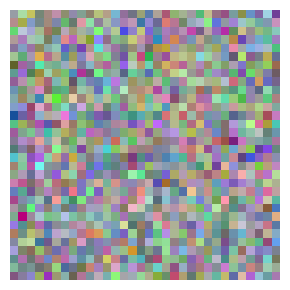

In [194]:
show_image(add_noise(next(iter(train_loader))[0], torch.tensor(400))[0].squeeze())

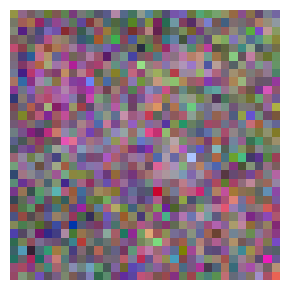

In [195]:
show_image(add_noise(train_[0], torch.tensor(250))[0].squeeze())

In [ ]:
def add_noise_batch(images):
    """
    Быстрое добавление шума к батчу изображений.

    Args:
        images: tensor формы [batch_size, channels, height, width]

    Returns:
        noisy_images: зашумленные изображения
        noise: добавленный шум
        timesteps: timestep для каждого изображения
    """
    batch_size = images.size(0)
    device = images.device
    timesteps = torch.randint(0, MAX_STEPS, (batch_size,), device=device)

    alpha_bar_t = alpha_bars.to(device)[timesteps]
    alpha_bar_t = alpha_bar_t.view(batch_size, *([1] * (images.dim() - 1)))

    noise = torch.randn_like(images)
    noisy_images = (
        torch.sqrt(alpha_bar_t) * images
        + torch.sqrt(1 - alpha_bar_t) * noise
    )

    return noisy_images, noise, timesteps

In [197]:
a = torch.zeros((64, 3, 32, 32))
a = add_noise_batch(a)

### training fn

In [198]:
import gc

def clear_cuda():
    torch.cuda.empty_cache()
    gc.collect()

In [199]:
def visualize_diffusion_steps(model, train_loader, device, n_steps_vis=6):
    """
    Показывает оригинал, зашумленные версии и попытки восстановления моделью.
    """
    model.eval()

    # 1. Берем одну картинку из датасета
    # Предполагаем, что train_loader возвращает (images, labels)
    data_iter = iter(train_loader)
    imgs = next(data_iter)
    original_img = imgs[0].unsqueeze(0).to(device) # (1, C, H, W)

    # 2. Выбираем шаги времени для визуализации (равномерно от шума к чистоте)
    # Например: [900, 700, 500, 300, 100] если T=1000
    timesteps = torch.linspace(MAX_STEPS - 1, 0, n_steps_vis, dtype=torch.long).to(device)

    fig, axes = plt.subplots(2, n_steps_vis + 1, figsize=(20, 8))

    # --- Верхний ряд: Оригиналы и Шум ---
    axes[0, 0].imshow(original_img[0].cpu().permute(1, 2, 0).clamp(-1, 1) * .5 + .5)
    axes[0, 0].set_title("Original")
    axes[0, 0].axis('off')

    noisy_imgs = []

    for i, t in enumerate(timesteps):
        # Добавляем шум к оригиналу для конкретного шага t
        alpha_bar_t = alpha_bars[t].item()
        noise = torch.randn_like(original_img)

        # Формула прямого процесса
        noisy_img = np.sqrt(alpha_bar_t) * original_img + np.sqrt(1 - alpha_bar_t) * noise

        noisy_imgs.append(noisy_img)

        # Отображаем зашумленную картинку
        axes[0, i+1].imshow(noisy_img[0].cpu().permute(1, 2, 0).clamp(-1, 1) * .5 + .5)
        axes[0, i+1].set_title(f"Noise t={t.item()}")
        axes[0, i+1].axis('off')

    # --- Нижний ряд: Восстановление моделью ---
    # Пытаемся восстановить x0 из каждого зашумленного состояния
    with torch.no_grad():
        for i, t in enumerate(timesteps):
            noisy_input = noisy_imgs[i]

            # Создаем тензор времени для модели
            t_tensor = torch.full((1,), t.item(), device=device, dtype=torch.long)

            # Предсказываем шум
            predicted_noise = model(noisy_input, t_tensor)

            # Восстанавливаем x0 по формуле: x0 = (xt - sqrt(1-a)*eps) / sqrt(a)
            alpha_bar_t = alpha_bars[t].item()
            pred_x0 = (noisy_input - np.sqrt(1 - alpha_bar_t) * predicted_noise) / np.sqrt(alpha_bar_t + 1e-8)

            # Отображаем результат
            axes[1, i+1].imshow(pred_x0[0].cpu().permute(1, 2, 0).clamp(-1, 1) * .5 + .5)
            axes[1, i+1].set_title(f"Reconstructed t={t.item()}")
            axes[1, i+1].axis('off')

    # Первая ячейка нижнего ряда пустая или с подписью
    axes[1, 0].text(0.5, 0.5, "Model\nRestoration", ha='center', va='center', fontsize=12)
    axes[1, 0].axis('off')

    plt.tight_layout()
    plt.show()
    model.train()

def denoise():
    visualize_diffusion_steps(model, train_loader, device)

In [207]:
@torch.no_grad()
def generate(n_images, n_steps=MAX_STEPS, temp=1.0, eta=0.0):
    # 1. Получаем устройство из модели
    device = next(model.parameters()).device
    alpha_bars_local = alpha_bars.to(device)

    # 2. Формируем индексы шагов сразу на нужном устройстве
    step_indices = torch.linspace(0, MAX_STEPS - 1, n_steps, dtype=torch.long, device=device)
    x = torch.randn(n_images, N_CHANNELS, WIDTH, WIDTH, device=device)

    for i in reversed(range(len(step_indices))):
        t = step_indices[i].item()
        alpha_bar_t = alpha_bars_local[t]

        if i > 0:
            t_prev = step_indices[i - 1].item()
            alpha_bar_prev = alpha_bars_local[t_prev]
        else:
            alpha_bar_prev = torch.tensor(1.0, device=device)

        t_tensor = torch.full((n_images,), t, device=device, dtype=torch.long)
        eps_pred = model(x, t_tensor)

        pred_x0 = (x - torch.sqrt(1.0 - alpha_bar_t) * eps_pred) / torch.sqrt(alpha_bar_t)
        dir_xt = torch.sqrt(1.0 - alpha_bar_prev) * eps_pred

        sigma_t = eta * torch.sqrt(
            (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t)
        ) * torch.sqrt(1.0 - alpha_bar_t / alpha_bar_prev)
        
        sigma_t = sigma_t * temp

        x = (
            torch.sqrt(alpha_bar_prev) * pred_x0
            + dir_xt
            + sigma_t * torch.randn_like(x)
        )

    return x

In [ ]:
def validate(criterion):
    model.eval()
    sum_loss = 0
    with torch.no_grad():
        for img in tqdm(test_loader, leave=False):
            img = img.to(device)
            noisy_img, noise, timesteps = add_noise_batch(img)

            predicted_noise = model(noisy_img, timesteps)
            loss = criterion(predicted_noise, noise)

            sum_loss += loss.item()
    return sum_loss / len(test_loader)

def train(n_epochs=10, LR=1e-4, save_dir='./models/', val_steps=1, img_show_steps=1):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-6)

    model.train()

    val_losses = []
    train_losses = []

    for epoch in range(n_epochs):
        train_loss = 0
        for img in tqdm(train_loader, leave=False):
            img = img.to(device)
            noisy_img, noise, timesteps = add_noise_batch(img)

            predicted_noise = model(noisy_img, timesteps)
            loss = criterion(predicted_noise, noise)
            train_loss += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss /= len(train_loader)
        train_losses.append(train_loss)
        scheduler.step()

        print(f'Epoch [{epoch + 1:3}/{n_epochs}] finished. Train MSE: {train_loss:.4f}', end=' | ')
        if epoch % val_steps == 0:
            val_loss = validate(criterion)
            val_losses.append(val_loss)
            print(f'Test MSE: {val_loss:.4f}')
        else:
            print()

        if epoch % img_show_steps == 0:
            denoise()

    print('Training completed')
    return val_losses, train_losses

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  1/10] finished. Train MSE: 0.6441 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.5497



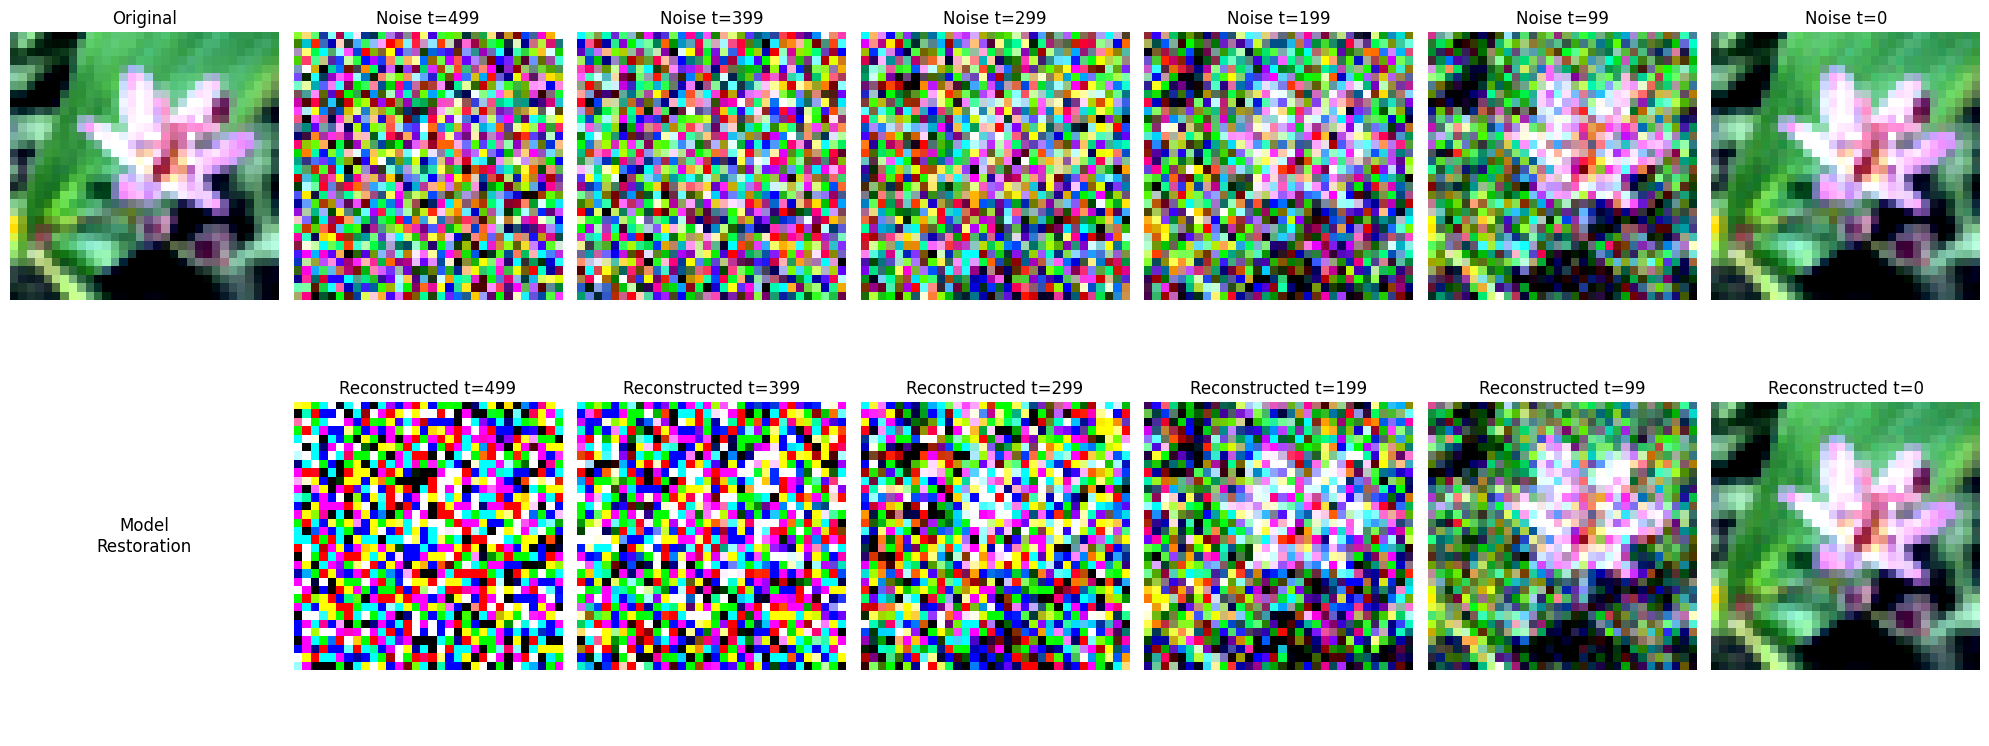

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  2/10] finished. Train MSE: 0.5039 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.4657



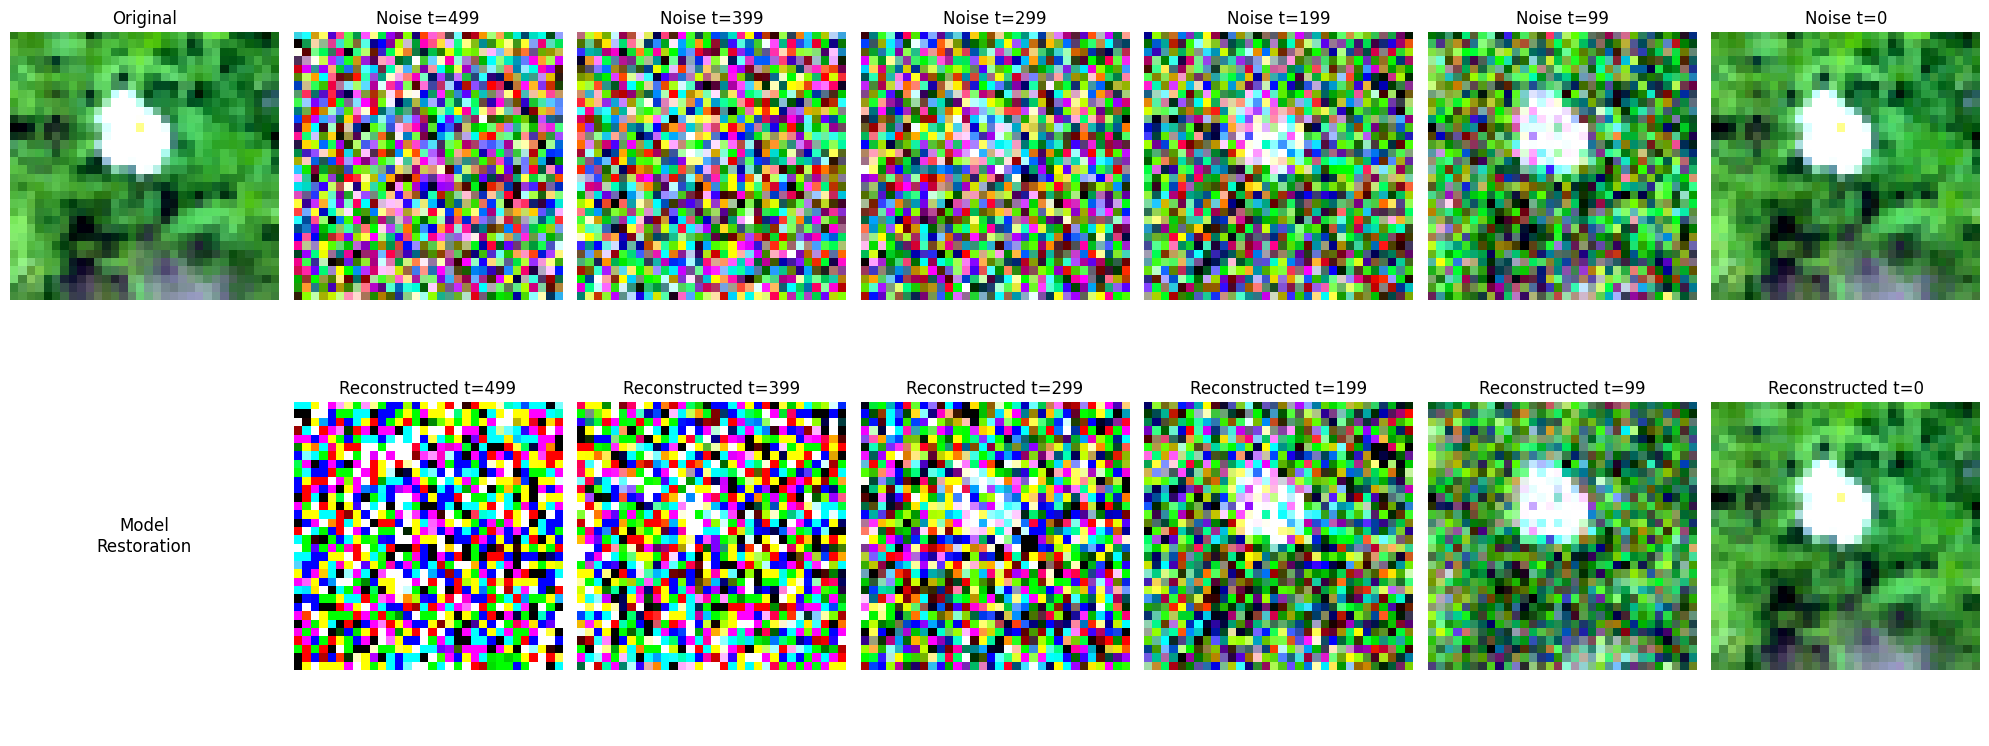

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  3/10] finished. Train MSE: 0.4341 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.4035



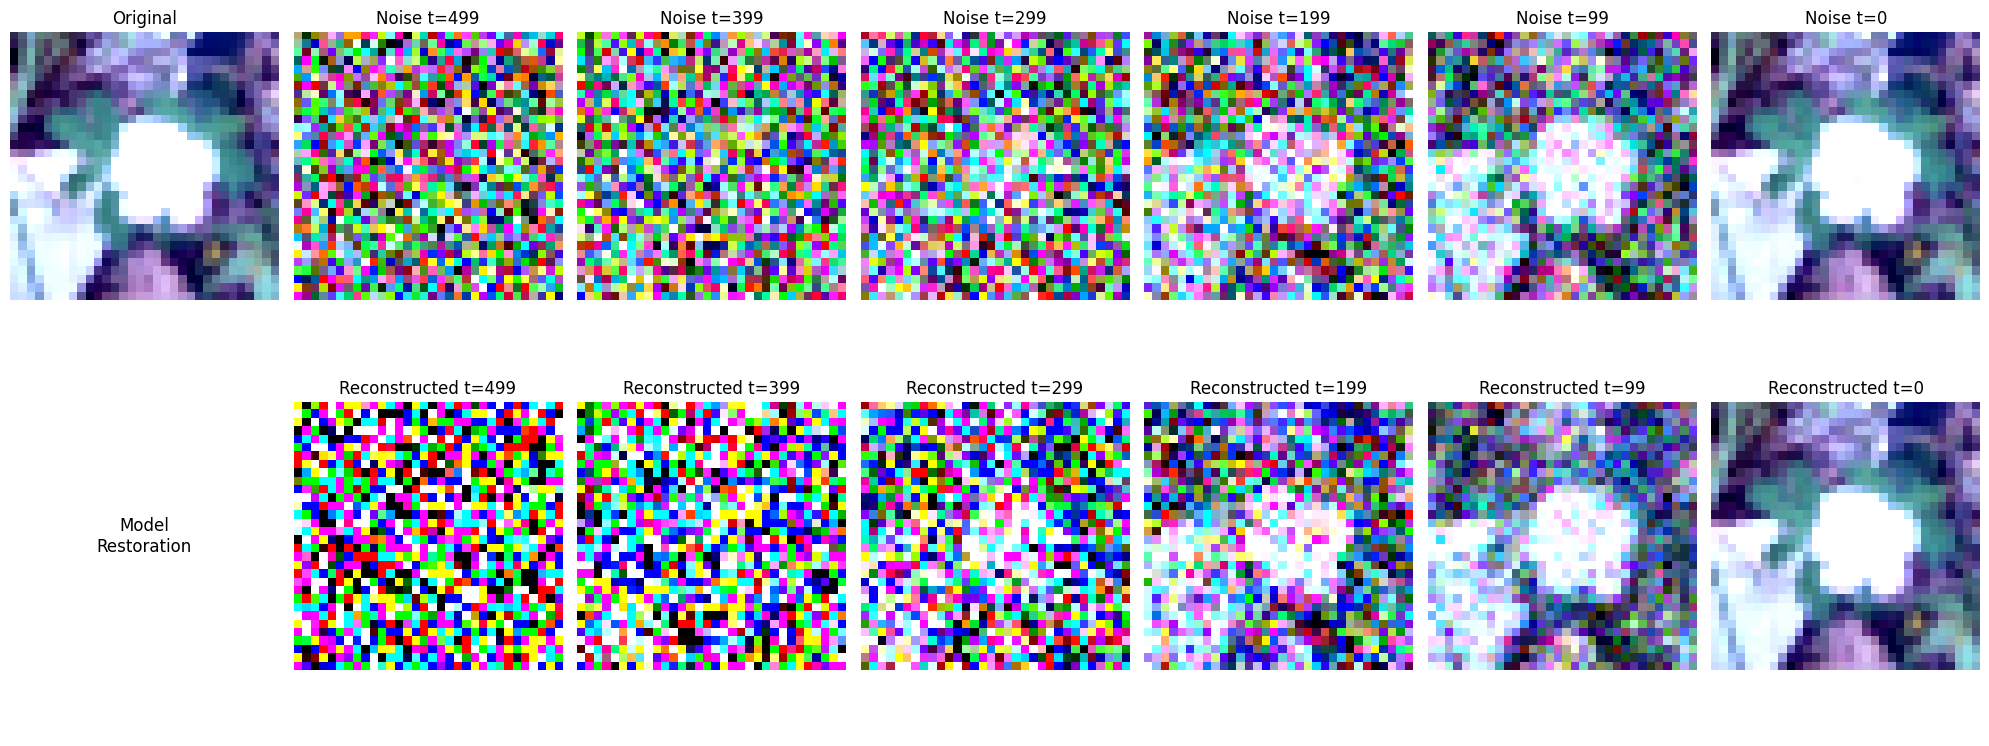

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  4/10] finished. Train MSE: 0.3690 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.3329



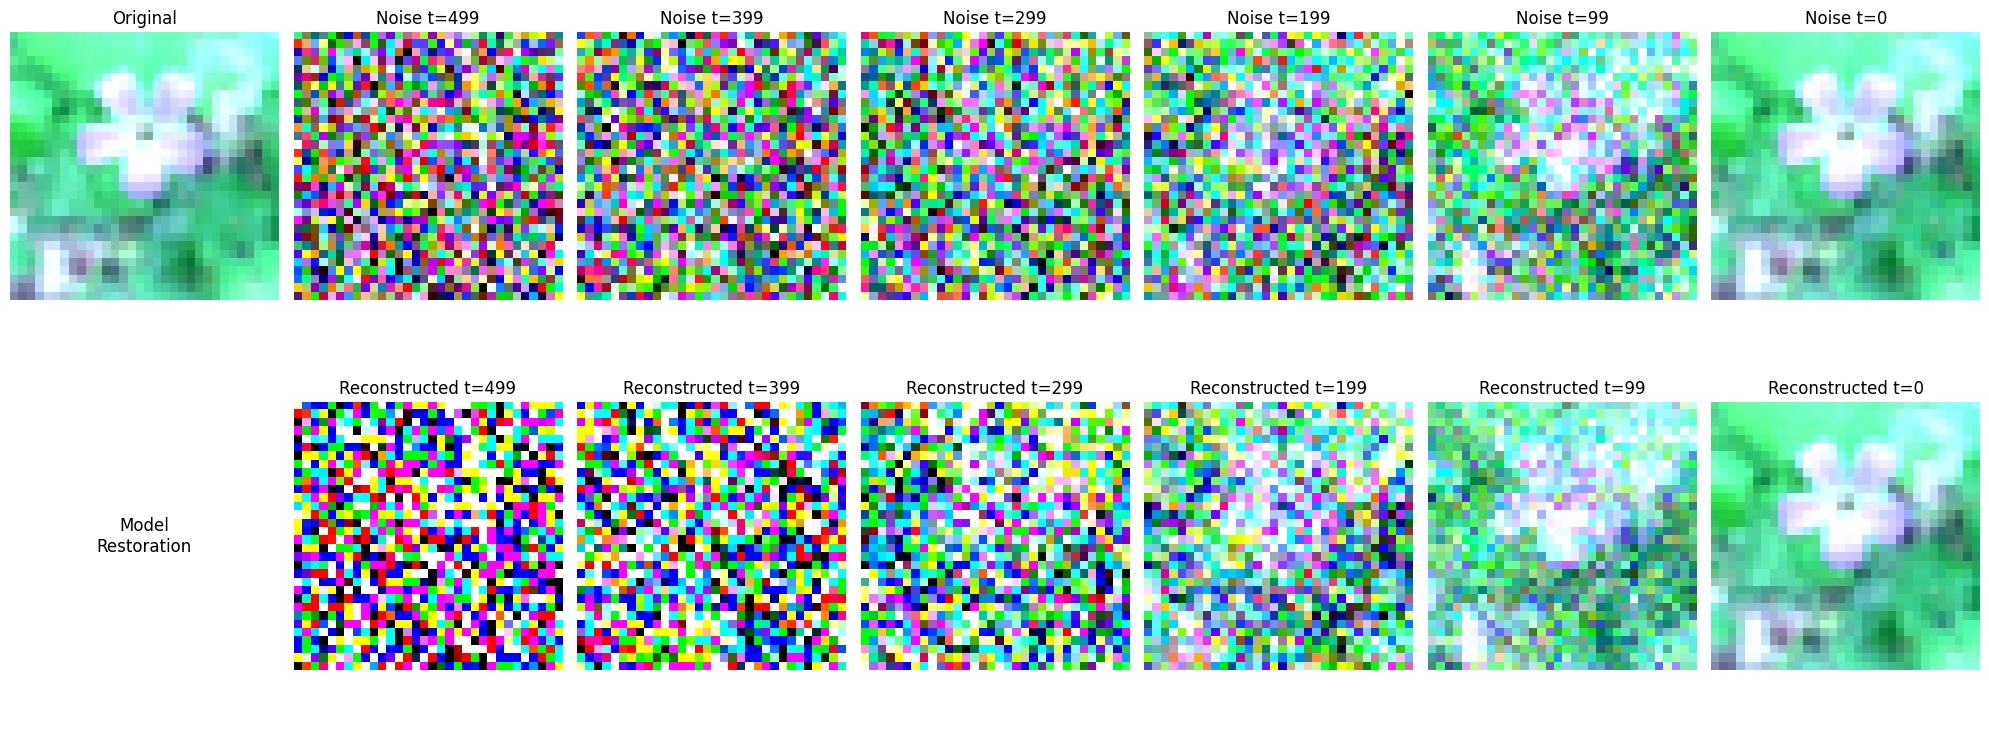

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  5/10] finished. Train MSE: 0.3044 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.2819



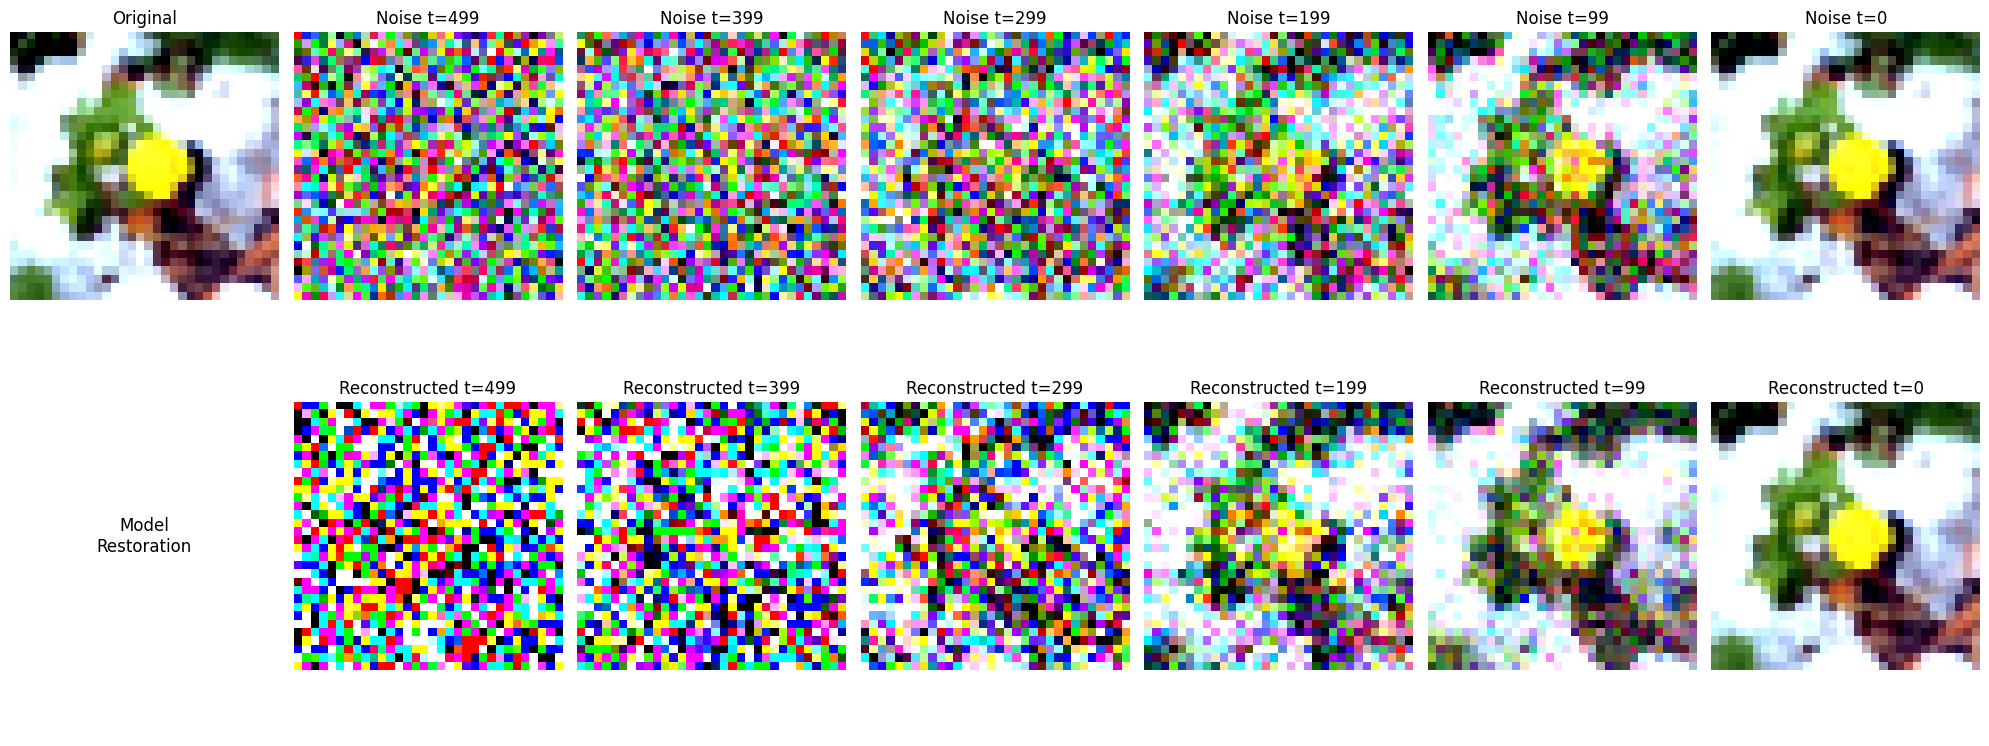

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  6/10] finished. Train MSE: 0.2579 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.2389



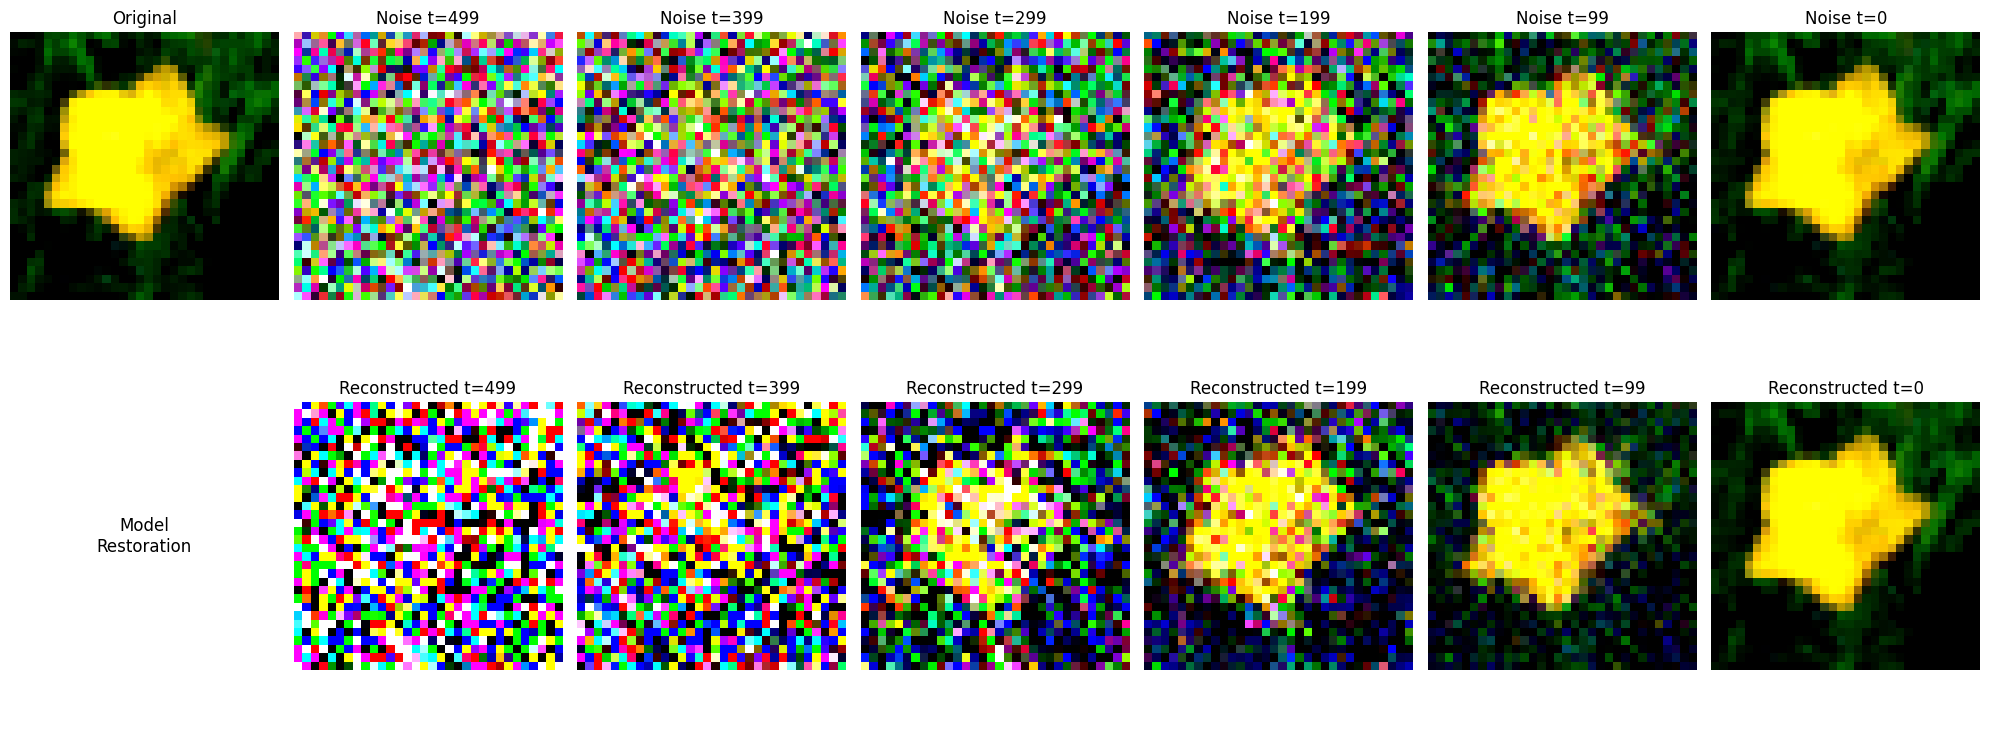

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  7/10] finished. Train MSE: 0.2224 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.2044



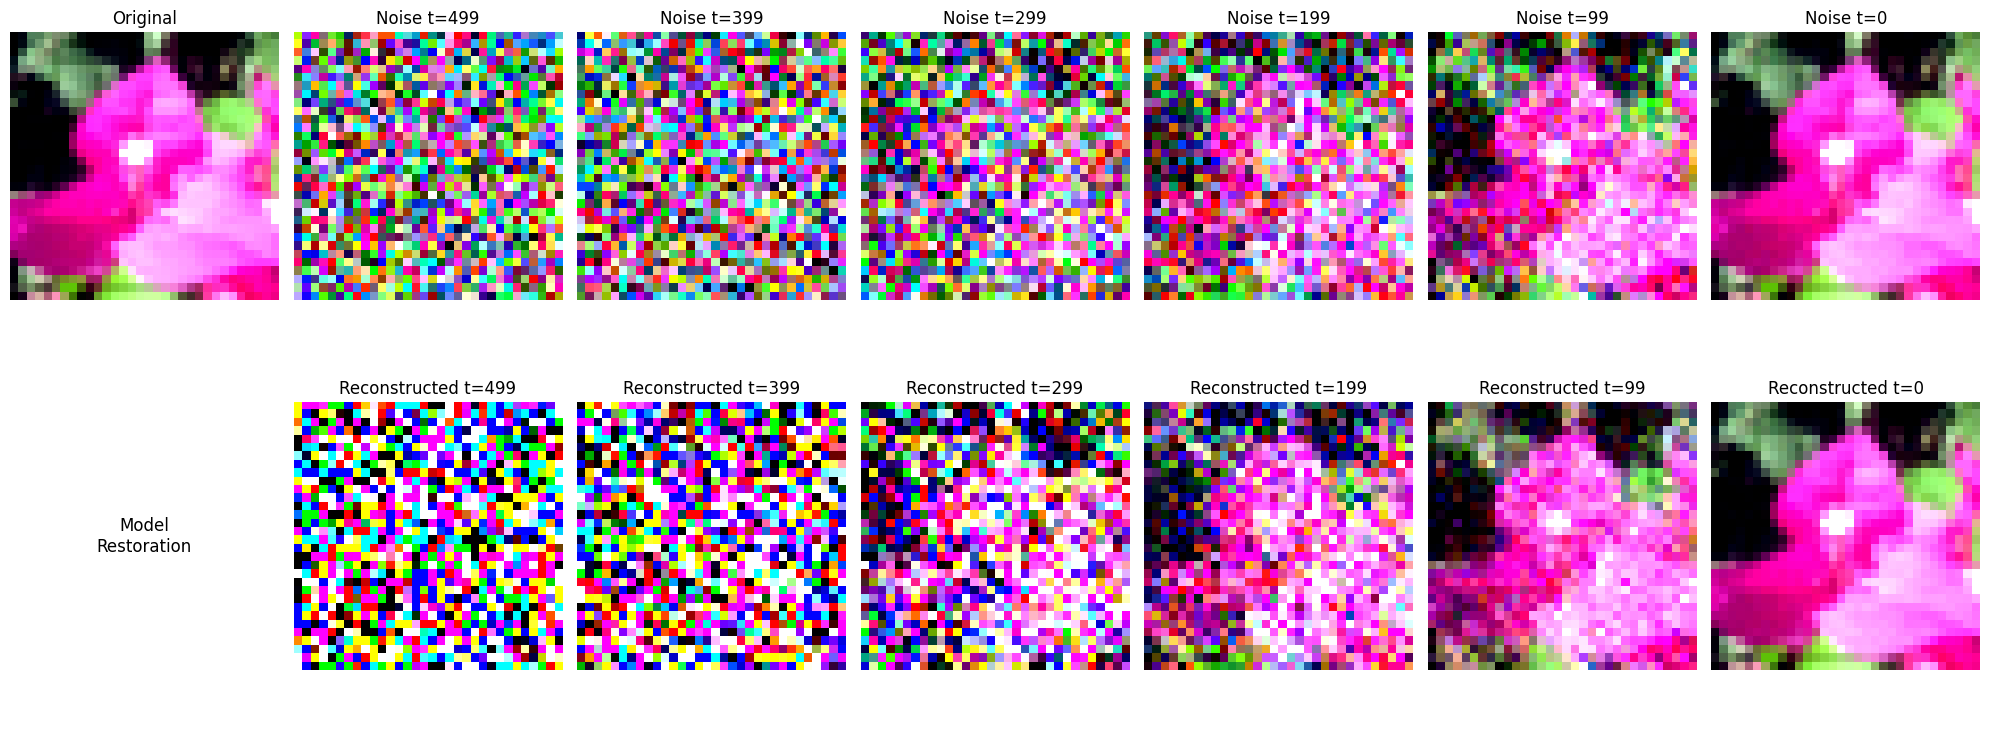

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  8/10] finished. Train MSE: 0.1971 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.1904



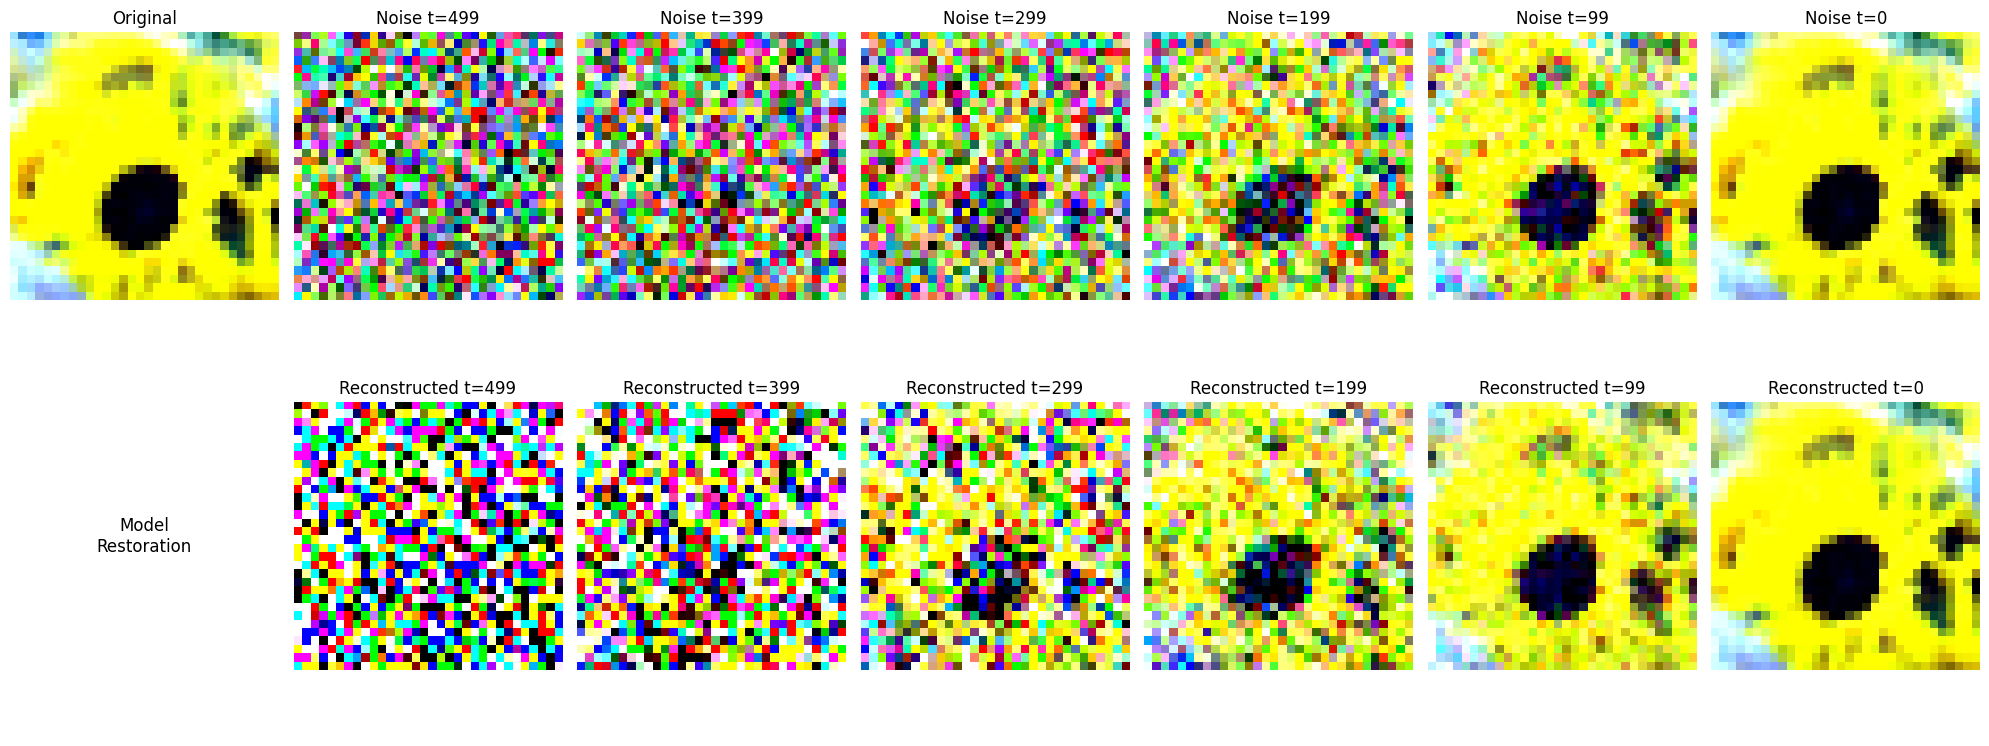

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [  9/10] finished. Train MSE: 0.1879 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.1860



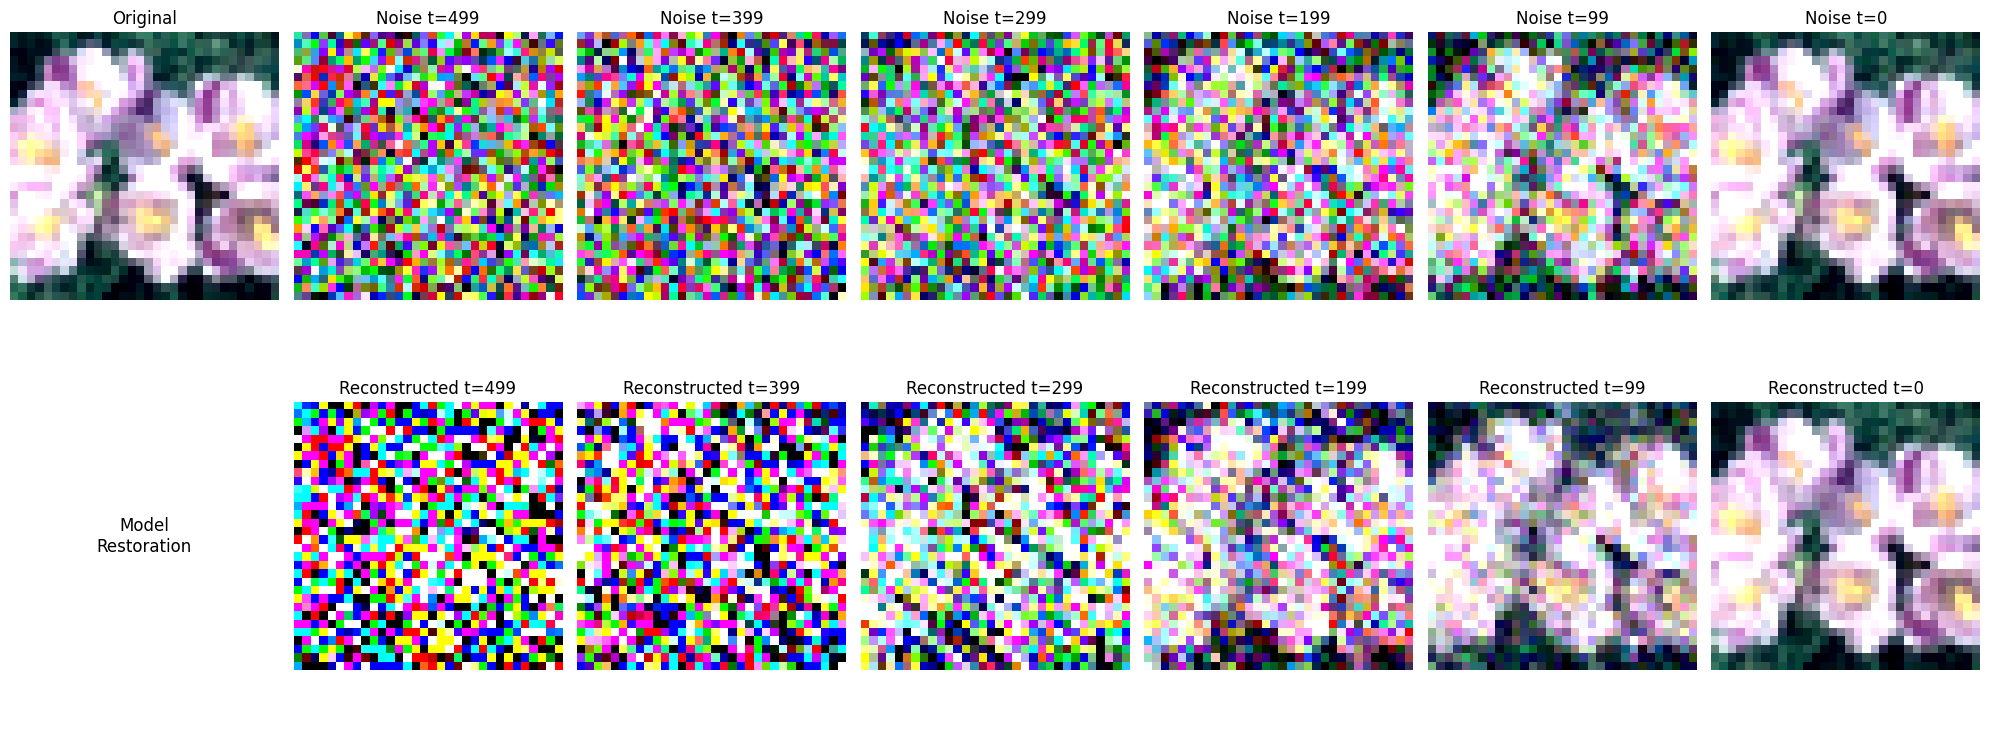

  0%|          | 0/200 [00:00<?, ?it/s]

Epoch [ 10/10] finished. Train MSE: 0.1808 | 

  0%|          | 0/58 [00:00<?, ?it/s]

Test MSE: 0.1821



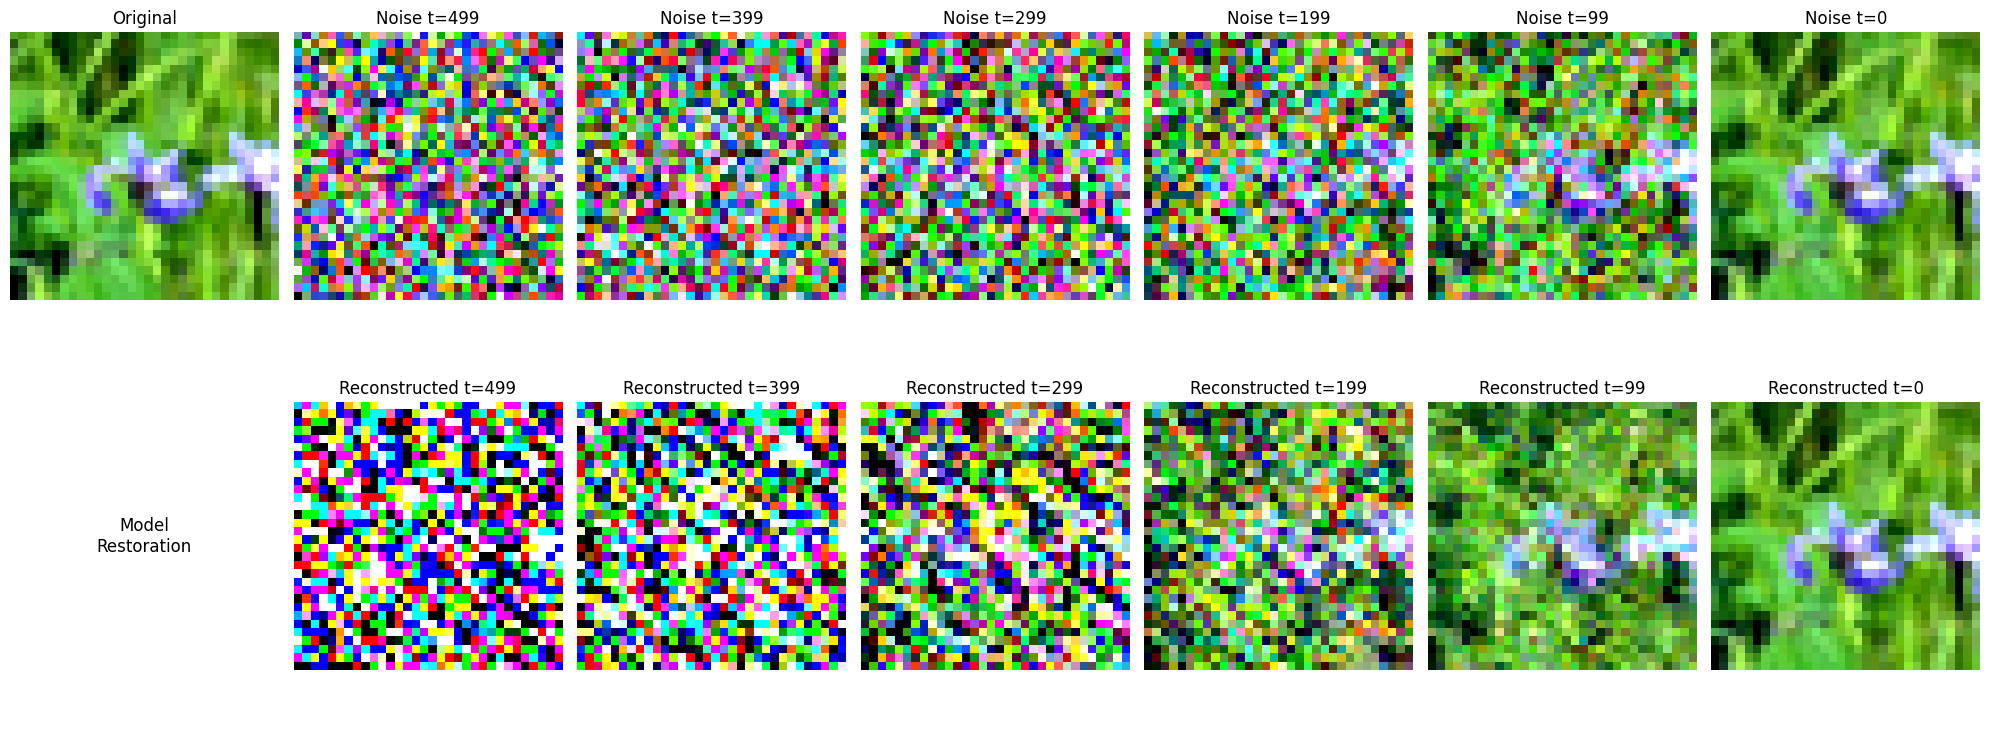

Training completed


In [202]:
LR = 1e-4
VAL_EPOCHS = 1
EPOCHS = 10

test_loss, train_loss = train(n_epochs=EPOCHS, LR=LR, val_steps=VAL_EPOCHS)

## Results

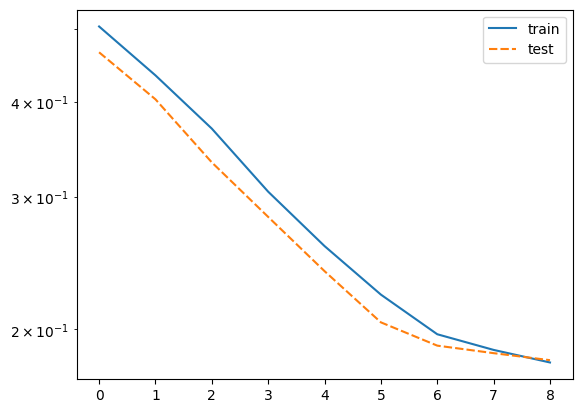

In [203]:
sns.lineplot(data={'train': train_loss[1:], 'test': test_loss[1:]})
plt.yscale('log')
plt.show()

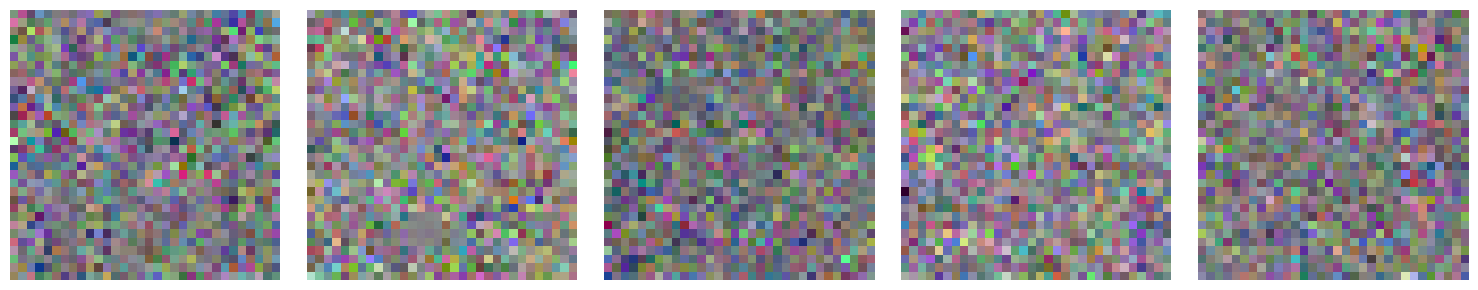

In [ ]:
def denormalize(images):
    mean = torch.tensor(MEAN, device=images.device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=images.device).view(1, 3, 1, 1)
    return images * std + mean

img = generate(n_images=5, n_steps=500)
img_rgb = denormalize(img)
show_image(img_rgb)

print(f"Normalized range: [{img.min().item():.3f}, {img.max().item():.3f}]")
print(f"Normalized mean: {img.mean().item():.3f}, std: {img.std().item():.3f}")
print(f"RGB range: [{img_rgb.min().item():.3f}, {img_rgb.max().item():.3f}]")
print(f"RGB mean: {img_rgb.mean().item():.3f}, std: {img_rgb.std().item():.3f}")

In [206]:
device = next(model.parameters()).device
x_test = torch.randn(1, N_CHANNELS, WIDTH, WIDTH, device=device)

# Проверяем выход на среднем шаге
t_test = torch.tensor([250], device=device, dtype=torch.long)
with torch.no_grad():
    out = model(x_test, t_test)

print(f"Диапазон выхода модели: [{out.min().item():.3f}, {out.max().item():.3f}]")
print(f"Среднее: {out.mean().item():.3f}, Std: {out.std().item():.3f}")

# Если диапазон примерно [-1.5, 1.5] или [-1, 1] -> модель 100% предсказывает x0 (картинку).
# Если диапазон примерно [-3, 3] или шире -> модель предсказывает шум (epsilon).

Диапазон выхода модели: [-2.179, 2.188]
Среднее: -0.011, Std: 0.648
